In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp13: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
np.random.seed(13); tf.random.set_seed(13)
hours=np.arange(24*365); demand=100+18*np.sin(2*np.pi*hours/24)+12*np.sin(2*np.pi*hours/(24*7))+0.015*hours+np.random.normal(0,4,len(hours))
series=pd.Series(demand).interpolate().values.reshape(-1,1)
sc=MinMaxScaler(); scaled=sc.fit_transform(series)
window=24
X=np.array([scaled[i-window:i,0] for i in range(window,len(scaled))]); y=scaled[window:,0]
split=int(len(X)*.8); Xtr,Xte=X[:split],X[split:]; ytr,yte=y[:split],y[split:]
Xtr=Xtr[...,None]; Xte=Xte[...,None]
model=tf.keras.Sequential([tf.keras.layers.Input((window,1)),tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(1)])
model.compile(optimizer="adam",loss="mse"); h=model.fit(Xtr,ytr,validation_split=.1,epochs=15,batch_size=64,verbose=0)
pred=sc.inverse_transform(model.predict(Xte,verbose=0)); actual=sc.inverse_transform(yte.reshape(-1,1))
print("MAE:",round(mean_absolute_error(actual,pred),3))
print("RMSE:",round(np.sqrt(mean_squared_error(actual,pred)),3))
plt.figure(figsize=(11,4)); plt.plot(actual[:300],label="Actual"); plt.plot(pred[:300],label="Predicted"); plt.xlabel("Test hour"); plt.ylabel("Electricity demand"); plt.title("Actual vs predicted demand"); plt.legend(); plt.grid(); plt.show()
plt.plot(h.history["loss"],label="Train"); plt.plot(h.history["val_loss"],label="Validation"); plt.legend(); plt.title("RNN training loss"); plt.show()

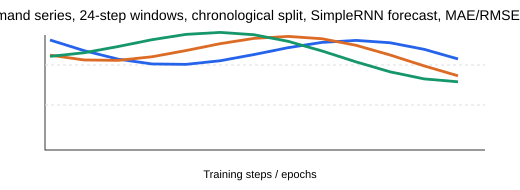

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.